# Indian Tea Production, 2017 – Mar 2026
**Curated Tea Board data → statistical analysis → 12-month-ahead forecasting model**

Data: seven Tea Board of India PDFs, curated by `src/extract.py` into
`data/processed/tea_production_master.csv` (one tidy table: month × geography ×
grower/category segment, plus the official annual totals).

Sections
1. Load the curated dataset
2. Exploratory & statistical analysis (trend, seasonality, structure, shocks)
3. Machine-learning model: forecast each area × grower series 12 months ahead,
   evaluated by rolling-origin backtest against seasonal baselines
4. Forecast for FY 2026-27

In [1]:
%matplotlib inline
import json
import warnings
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from statsmodels.tsa.seasonal import STL

warnings.filterwarnings("ignore")


def find_root() -> Path:
    here = Path.cwd()
    for p in (here, *here.parents):
        if (p / "data" / "processed").exists():
            return p
    raise FileNotFoundError("run src/extract.py first")


ROOT = find_root()
DATA = ROOT / "data" / "processed"
REPORTS = ROOT / "reports"
FIG = REPORTS / "figures"
FIG.mkdir(parents=True, exist_ok=True)

# ---- chart system: one palette, entity-fixed colours, recessive chrome
SURFACE, INK, INK2, MUTED, GRID, BASE = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ = LinearSegmentedColormap.from_list("blue_seq", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5",
                                                     "#256abf", "#184f95", "#0d366b"])
ZONE_COLOR = {"North India": CAT[0], "South India": CAT[1]}
STATE_ORDER = ["Assam", "West Bengal", "Others (North)", "Tamil Nadu", "Kerala", "Karnataka"]
STATE_COLOR = dict(zip(STATE_ORDER, CAT))
MODEL_COLOR = {"Actual": INK, "Seasonal naive": MUTED}

mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 10,
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.edgecolor": BASE, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.7,
    "grid.linestyle": "-", "axes.axisbelow": True,
    "xtick.major.size": 0, "ytick.major.size": 0, "lines.linewidth": 2,
    "legend.frameon": False, "legend.fontsize": 9,
})


def titled(ax, title: str, subtitle: str = "") -> None:
    ax.set_title(title, loc="left", fontsize=13, fontweight="semibold", color=INK, pad=24 if subtitle else 10)
    if subtitle:
        ax.text(0, 1.02, subtitle, transform=ax.transAxes, fontsize=9.5, color=INK2, va="bottom")


def save(fig, name: str) -> None:
    fig.tight_layout()
    fig.savefig(FIG / name, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)


STATS: dict = {}

## 1. Load the curated dataset

In [2]:
master = pd.read_csv(DATA / "tea_production_master.csv")
mon = master[master.period_type == "month"].copy()
mon["date"] = pd.to_datetime(mon["date"])
grow = mon[mon.breakdown == "grower"]
catg = mon[mon.breakdown == "category"]


def series(geo: str, seg: str = "Total") -> pd.Series:
    s = grow[(grow.geography == geo) & (grow.segment == seg)].set_index("date")["production_mkg"]
    return s.sort_index().asfreq("MS")


india = series("All India")
print(f"Master table: {len(master):,} rows, {master.shape[1]} columns")
print(f"Monthly coverage: {india.index.min():%b %Y} – {india.index.max():%b %Y} ({len(india)} months)")
print(master.groupby(["period_type", "breakdown"]).size().rename("rows").to_string())
print("\nQA checks:")
print(pd.read_csv(DATA / "qa_checks.csv")[["check", "result"]].to_string(index=False))

# Annual calendar-year table: official FINAL totals 2017-2024 + 2025 from final monthly data
ann = master[master.period_type == "calendar_year"].pivot(index="period", columns="geography",
                                                          values="production_mkg")
ann.index = ann.index.astype(int)
for z in ("North India", "South India", "All India"):
    ann.loc[2025, z] = series(z).loc["2025"].sum()
ann = ann.sort_index()
fy = master[master.period_type == "fiscal_year"].pivot(index="period", columns="geography",
                                                       values="production_mkg")
fy.loc["2025-26"] = [series(z).loc["2025-04":"2026-03"].sum() for z in fy.columns]
print("\nCalendar-year production (M kg):\n", ann.round(2).to_string())

Master table: 4,746 rows, 17 columns
Monthly coverage: Jan 2019 – Mar 2026 (87 months)
period_type    breakdown
calendar_year  grower         24
fiscal_year    grower         24
month          category     1044
               grower       3654

QA checks:
                                                                                check result
                                    Duplicate months agree across files (same status)   PASS
                                         Provisional vs Final overlap (informational)   PASS
                                             BG + SG = Total (every row, every month)   PASS
                                             Hierarchy: Assam Valley + Cachar = Assam   PASS
                                 Hierarchy: Dooars + Terai + Darjeeling = West Bengal   PASS
                                Hierarchy: Assam + West Bengal + Others = North India   PASS
                             Hierarchy: Tamil Nadu + Kerala + Karnataka = South India   PASS


## 2. Exploratory & statistical analysis
### 2.1 Long-run trend

{
  "cy2017": 1321.76,
  "cy2025": 1395.53,
  "cagr_2017_2025_pct": 0.68,
  "kendall_tau": 0.389,
  "kendall_p": 0.18,
  "ols_slope_mkg_per_year": 5.1,
  "ols_p": 0.434,
  "record_year": 2025,
  "record_mkg": 1395.53,
  "yoy_pct": {
    "2018": 1.28,
    "2019": 3.84,
    "2020": -9.54,
    "2021": 6.8,
    "2022": 1.73,
    "2023": 2.0,
    "2024": -6.47,
    "2025": 7.06
  }
}


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


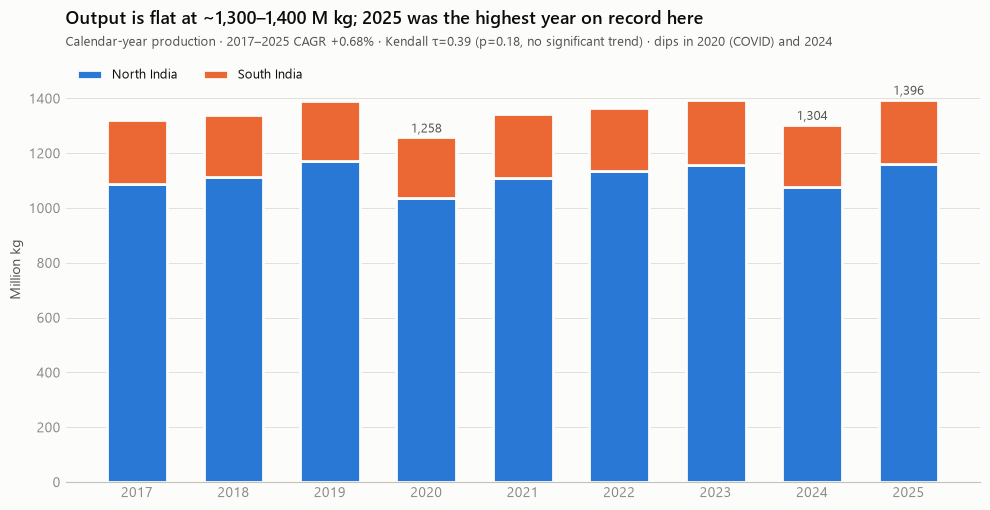

In [3]:
yrs = ann.index.values
cagr = (ann.loc[2025, "All India"] / ann.loc[2017, "All India"]) ** (1 / 8) - 1
tau, p_tau = stats.kendalltau(yrs, ann["All India"])
lr = stats.linregress(yrs, ann["All India"])
STATS["trend"] = {
    "cy2017": round(ann.loc[2017, "All India"], 2), "cy2025": round(ann.loc[2025, "All India"], 2),
    "cagr_2017_2025_pct": round(100 * cagr, 2),
    "kendall_tau": round(tau, 3), "kendall_p": round(p_tau, 3),
    "ols_slope_mkg_per_year": round(lr.slope, 2), "ols_p": round(lr.pvalue, 3),
    "record_year": int(ann["All India"].idxmax()), "record_mkg": round(ann["All India"].max(), 2),
    "yoy_pct": (ann["All India"].pct_change() * 100).round(2).dropna().to_dict(),
}
print(json.dumps(STATS["trend"], indent=2))

fig, ax = plt.subplots(figsize=(10, 5.2))
x = np.arange(len(ann))
ax.bar(x, ann["North India"], color=ZONE_COLOR["North India"], width=0.62,
       edgecolor=SURFACE, linewidth=2, label="North India")
ax.bar(x, ann["South India"], bottom=ann["North India"], color=ZONE_COLOR["South India"], width=0.62,
       edgecolor=SURFACE, linewidth=2, label="South India")
for yr in (ann["All India"].idxmax(), ann["All India"].idxmin(), 2024):
    i = list(ann.index).index(yr)
    ax.text(i, ann.loc[yr, "All India"] + 18, f"{ann.loc[yr, 'All India']:,.0f}", ha="center",
            fontsize=9, color=INK2)
ax.set_xticks(x, ann.index)
ax.set_ylabel("Million kg")
ax.set_ylim(0, 1550)
ax.legend(loc="upper left", ncol=2, bbox_to_anchor=(0, 1.0))
titled(ax, "Output is flat at ~1,300–1,400 M kg; 2025 was the highest year on record here",
       f"Calendar-year production · 2017–2025 CAGR {100 * cagr:+.2f}% · Kendall τ={tau:.2f} "
       f"(p={p_tau:.2f}, no significant trend) · dips in 2020 (COVID) and 2024")
save(fig, "01_annual_production.png")

### 2.2 Seasonality — when is tea made?

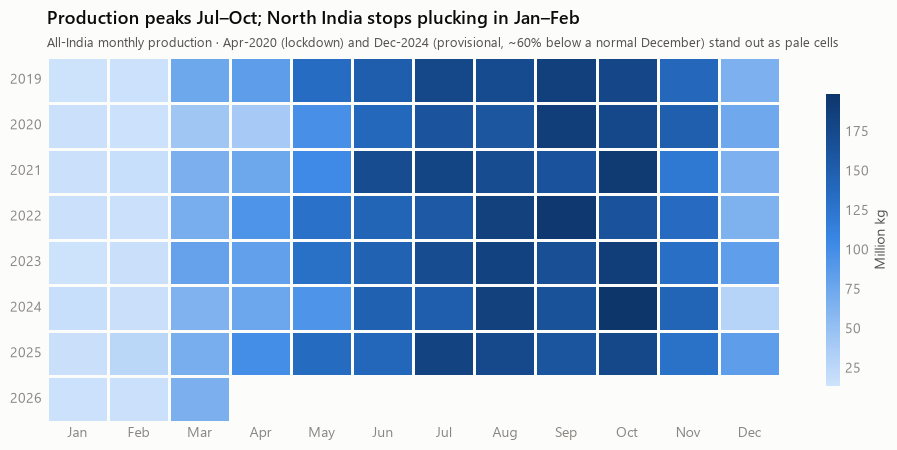

{
  "North India": {
    "coef_variation_pct": 62.2,
    "peak_month": 8,
    "trough_month": 1,
    "kruskal_H": 78.2,
    "kruskal_p": 3.25e-12,
    "jul_oct_share_pct": 55.5
  },
  "South India": {
    "coef_variation_pct": 21.2,
    "peak_month": 6,
    "trough_month": 2,
    "kruskal_H": 53.2,
    "kruskal_p": 1.63e-07,
    "jul_oct_share_pct": 35.4
  }
}


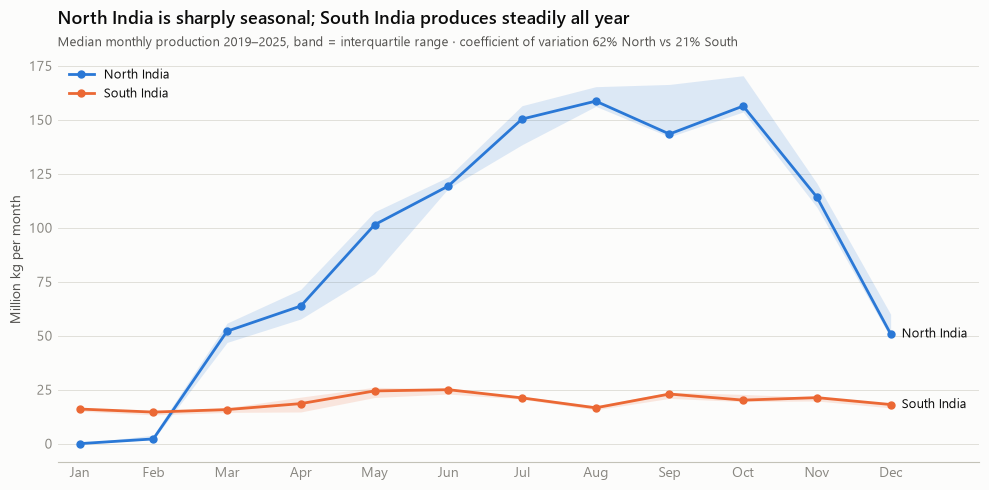

In [4]:
hm = india.to_frame("v").assign(Year=india.index.year, Month=india.index.strftime("%b"))
hm = hm.pivot(index="Year", columns="Month", values="v")[
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]]
fig, ax = plt.subplots(figsize=(10, 4.6))
sns.heatmap(hm, cmap=SEQ, linewidths=2, linecolor=SURFACE, ax=ax,
            cbar_kws={"label": "Million kg", "shrink": 0.8})
ax.grid(False)
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(axis="y", rotation=0)
titled(ax, "Production peaks Jul–Oct; North India stops plucking in Jan–Feb",
       "All-India monthly production · Apr-2020 (lockdown) and Dec-2024 (provisional, ~60% below a normal December) "
       "stand out as pale cells")
save(fig, "02_seasonality_heatmap.png")

prof = []
for z in ("North India", "South India"):
    s = series(z).loc[:"2025-12"]
    d = s.to_frame("v").assign(m=s.index.month)
    q = d.groupby("m")["v"].describe()[["25%", "50%", "75%"]]
    prof.append(q.assign(zone=z))
    kw = stats.kruskal(*[g["v"].values for _, g in d.groupby("m")])
    STATS.setdefault("seasonality", {})[z] = {
        "coef_variation_pct": round(100 * s.std() / s.mean(), 1),
        "peak_month": int(q["50%"].idxmax()), "trough_month": int(q["50%"].idxmin()),
        "kruskal_H": round(kw.statistic, 1), "kruskal_p": float(f"{kw.pvalue:.2e}"),
        "jul_oct_share_pct": round(100 * d[d.m.between(7, 10)]["v"].sum() / d["v"].sum(), 1),
    }
print(json.dumps(STATS["seasonality"], indent=2))

fig, ax = plt.subplots(figsize=(10, 5))
for q in prof:
    z = q["zone"].iloc[0]
    ax.fill_between(q.index, q["25%"], q["75%"], color=ZONE_COLOR[z], alpha=0.15, linewidth=0)
    ax.plot(q.index, q["50%"], color=ZONE_COLOR[z], marker="o", markersize=5, label=z)
    ax.text(12.15, q["50%"].iloc[-1], z, color=INK, fontsize=9.5, va="center")
ax.set_xticks(range(1, 13), ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_xlim(0.7, 13.2)
ax.set_ylabel("Million kg per month")
ax.legend(loc="upper left")
cvn, cvs = (STATS["seasonality"][z]["coef_variation_pct"] for z in ("North India", "South India"))
titled(ax, "North India is sharply seasonal; South India produces steadily all year",
       f"Median monthly production 2019–2025, band = interquartile range · coefficient of variation "
       f"{cvn:.0f}% North vs {cvs:.0f}% South")
save(fig, "03_seasonal_profile.png")

### 2.3 Structural shift — small growers now make most of India's tea

{
  "sg_share_2019_pct": 49.3,
  "sg_share_2025_pct": 56.6,
  "trend_pp_per_year": 1.12,
  "trend_r2": 0.957,
  "trend_p": 0.0001,
  "by_state_2019_vs_2025": {
    "Assam": [
      44.9,
      49.4
    ],
    "West Bengal": [
      55.8,
      67.8
    ],
    "Tamil Nadu": [
      61.2,
      68.3
    ],
    "Kerala": [
      19.7,
      20.1
    ]
  },
  "bg_2019_mkg": 705.1,
  "bg_2025_mkg": 605.0
}


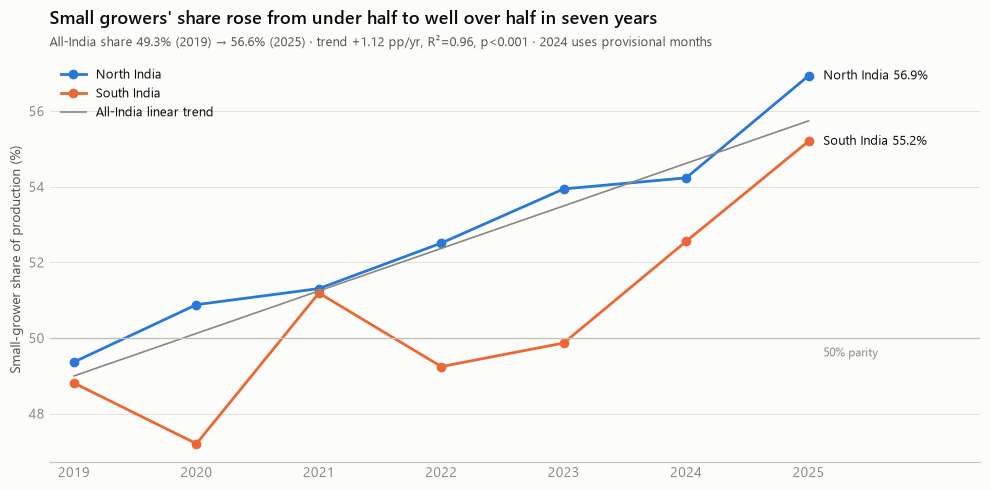

In [5]:
yr_tot = grow[(grow.date < "2026-01-01")].assign(year=lambda d: d.date.dt.year)
sg = (yr_tot[yr_tot.segment.isin(["SG", "Total"])]
      .groupby(["year", "geography", "segment"])["production_mkg"].sum().unstack("segment"))
sg_share = (100 * sg["SG"] / sg["Total"]).unstack("geography")
lr_sg = stats.linregress(sg_share.index, sg_share["All India"])
STATS["small_growers"] = {
    "sg_share_2019_pct": round(sg_share.loc[2019, "All India"], 1),
    "sg_share_2025_pct": round(sg_share.loc[2025, "All India"], 1),
    "trend_pp_per_year": round(lr_sg.slope, 2), "trend_r2": round(lr_sg.rvalue ** 2, 3),
    "trend_p": round(lr_sg.pvalue, 4),
    "by_state_2019_vs_2025": {s: [round(sg_share.loc[2019, s], 1), round(sg_share.loc[2025, s], 1)]
                              for s in ["Assam", "West Bengal", "Tamil Nadu", "Kerala"]},
    "bg_2019_mkg": round(sg.loc[(2019, "All India"), "Total"] - sg.loc[(2019, "All India"), "SG"], 1),
    "bg_2025_mkg": round(sg.loc[(2025, "All India"), "Total"] - sg.loc[(2025, "All India"), "SG"], 1),
}
print(json.dumps(STATS["small_growers"], indent=2))

fig, ax = plt.subplots(figsize=(10, 5))
for z in ("North India", "South India"):
    ax.plot(sg_share.index, sg_share[z], color=ZONE_COLOR[z], marker="o", markersize=6, label=z)
    ax.text(2025.12, sg_share.loc[2025, z], f"{z} {sg_share.loc[2025, z]:.1f}%", fontsize=9, va="center")
fit = lr_sg.intercept + lr_sg.slope * sg_share.index
ax.plot(sg_share.index, fit, color=MUTED, linewidth=1.2, label="All-India linear trend")
ax.axhline(50, color=BASE, linewidth=1)
ax.text(2025.12, 49.75, "50% parity", fontsize=8.5, color=MUTED, va="top")
ax.set_xlim(2018.8, 2026.4)
ax.set_xticks(range(2019, 2026))
ax.set_ylabel("Small-grower share of production (%)")
ax.legend(loc="upper left")
titled(ax, "Small growers' share rose from under half to well over half in seven years",
       f"All-India share {STATS['small_growers']['sg_share_2019_pct']}% (2019) → "
       f"{STATS['small_growers']['sg_share_2025_pct']}% (2025) · trend +{lr_sg.slope:.2f} pp/yr, "
       f"R²={lr_sg.rvalue ** 2:.2f}, p<0.001 · 2024 uses provisional months")
save(fig, "04_small_grower_share.png")

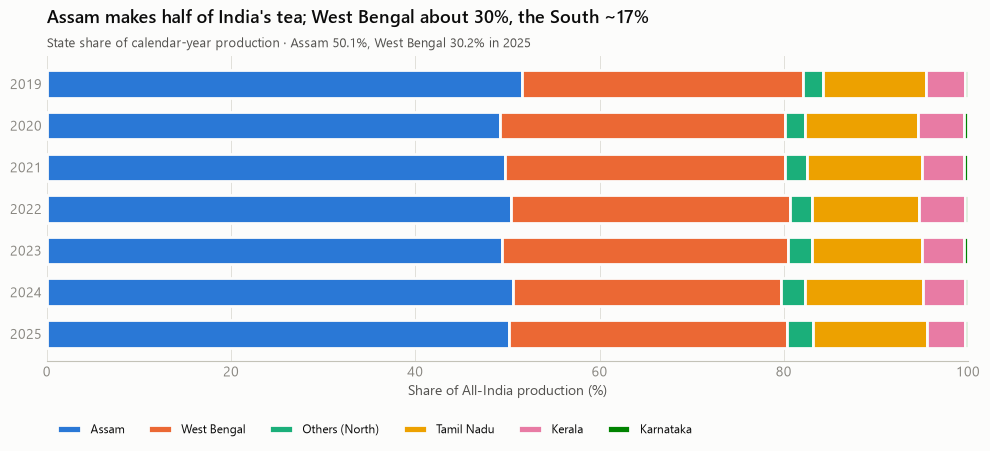

In [6]:
st = (grow[(grow.geo_level.isin(["state", "area"])) & (grow.segment == "Total") & (grow.date < "2026-01-01")]
      .assign(year=lambda d: d.date.dt.year))
st = st[st.geography.isin(["Assam", "West Bengal", "Others (NE & HP etc.)", "Tamil Nadu", "Kerala", "Karnataka"])]
st = st.assign(state=st.geography.replace({"Others (NE & HP etc.)": "Others (North)"}))
share = st.pivot_table(index="year", columns="state", values="production_mkg", aggfunc="sum")[STATE_ORDER]
share = 100 * share.div(share.sum(axis=1), axis=0)
STATS["state_share_pct"] = share.round(1).loc[[2019, 2025]].to_dict("index")

fig, ax = plt.subplots(figsize=(10, 4.8))
left = np.zeros(len(share))
for s in STATE_ORDER:
    ax.barh(share.index.astype(str), share[s], left=left, color=STATE_COLOR[s], edgecolor=SURFACE,
            linewidth=2, height=0.66, label=s)
    left += share[s].values
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.set_xlabel("Share of All-India production (%)")
ax.legend(ncol=6, loc="lower left", bbox_to_anchor=(0, -0.28), fontsize=8.5)
titled(ax, "Assam makes half of India's tea; West Bengal about 30%, the South ~17%",
       f"State share of calendar-year production · Assam {share.loc[2025, 'Assam']:.1f}%, "
       f"West Bengal {share.loc[2025, 'West Bengal']:.1f}% in 2025")
save(fig, "05_state_share.png")

### 2.4 Product mix — CTC dominates, Orthodox is growing

{
  "ctc_share_2025_pct": 88.0,
  "orthodox_mkg": {
    "2019": 139.04,
    "2020": 96.41,
    "2021": 113.84,
    "2022": 130.58,
    "2023": 118.17,
    "2024": 118.67,
    "2025": 149.04
  },
  "orthodox_share_pct": {
    "2019": 10.0,
    "2020": 7.7,
    "2021": 8.5,
    "2022": 9.6,
    "2023": 8.5,
    "2024": 9.2,
    "2025": 10.7
  },
  "green_share_2025_pct": 1.35
}


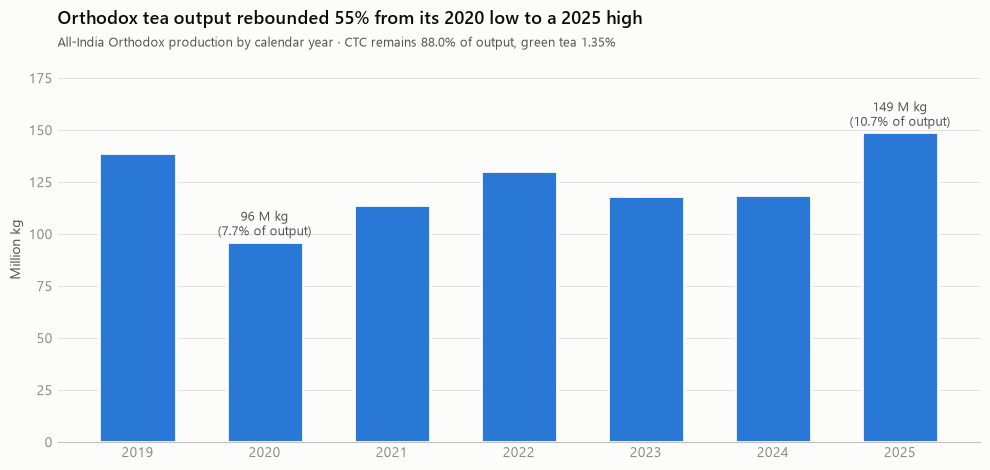

In [7]:
cy_cat = (catg[(catg.geography == "All India") & (catg.date < "2026-01-01")]
          .assign(year=lambda d: d.date.dt.year)
          .pivot_table(index="year", columns="segment", values="production_mkg", aggfunc="sum"))
cy_cat["ortho_share"] = 100 * cy_cat["Orthodox"] / cy_cat["Total"]
STATS["category"] = {
    "ctc_share_2025_pct": round(100 * cy_cat.loc[2025, "CTC"] / cy_cat.loc[2025, "Total"], 1),
    "orthodox_mkg": cy_cat["Orthodox"].round(2).to_dict(),
    "orthodox_share_pct": cy_cat["ortho_share"].round(1).to_dict(),
    "green_share_2025_pct": round(100 * cy_cat.loc[2025, "Green"] / cy_cat.loc[2025, "Total"], 2),
}
print(json.dumps(STATS["category"], indent=2))

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.bar(cy_cat.index, cy_cat["Orthodox"], color=CAT[0], width=0.6, edgecolor=SURFACE, linewidth=2)
for yr in (2020, 2025):
    ax.text(yr, cy_cat.loc[yr, "Orthodox"] + 3, f"{cy_cat.loc[yr, 'Orthodox']:.0f} M kg\n"
            f"({cy_cat.loc[yr, 'ortho_share']:.1f}% of output)", ha="center", fontsize=9, color=INK2)
ax.set_ylim(0, 185)
ax.set_ylabel("Million kg")
titled(ax, "Orthodox tea output rebounded 55% from its 2020 low to a 2025 high",
       f"All-India Orthodox production by calendar year · CTC remains "
       f"{STATS['category']['ctc_share_2025_pct']}% of output, green tea "
       f"{STATS['category']['green_share_2025_pct']}%")
save(fig, "06_orthodox_production.png")

### 2.5 Shocks — COVID-19 (2020) and the December-2024 shortfall

{
  "apr_may_2020_vs_2019_pct": -37.9,
  "cy2020_vs_2019_pct": -9.5,
  "dec2024_mkg": 29.39,
  "dec_other_years_mean": 73.3,
  "dec2024_zscore": -4.71
}
  period_type  period        zone   value                              source_file  sum_of_months   gap  months_include_provisional
  fiscal_year 2019-20 North India 1140.69 Production_Region_wise_FINAL_pdf9516.pdf        1140.69  0.00                       False
  fiscal_year 2019-20 South India  220.12 Production_Region_wise_FINAL_pdf9516.pdf         220.12  0.00                       False
  fiscal_year 2019-20   All India 1360.81 Production_Region_wise_FINAL_pdf9516.pdf        1360.81  0.00                       False
  fiscal_year 2020-21 North India 1050.80 Production_Region_wise_FINAL_pdf9516.pdf        1050.80  0.00                       False
  fiscal_year 2020-21 South India  232.23 Production_Region_wise_FINAL_pdf9516.pdf         232.23  0.00                       False
  fiscal_year 2020-21   All India 1283.03 Production_Re

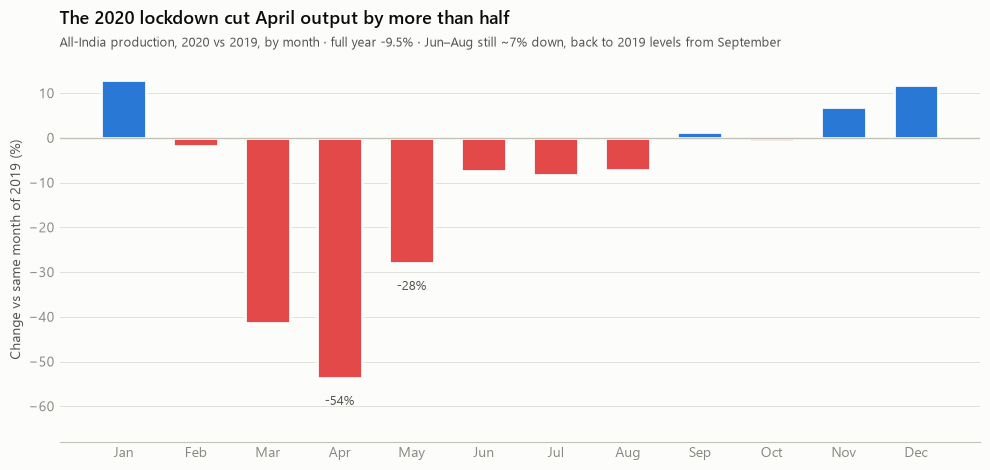

In [8]:
yoy20 = 100 * (india.loc["2020"].values / india.loc["2019"].values - 1)
dec = india[india.index.month == 12]
z_dec24 = (dec.loc["2024-12-01"] - dec.drop(pd.Timestamp("2024-12-01")).mean()) / dec.drop(pd.Timestamp("2024-12-01")).std()
recon = pd.read_csv(DATA / "annual_reconciliation.csv")
STATS["shocks"] = {
    "apr_may_2020_vs_2019_pct": round(100 * (india.loc["2020-04":"2020-05"].sum() /
                                             india.loc["2019-04":"2019-05"].sum() - 1), 1),
    "cy2020_vs_2019_pct": round(100 * (ann.loc[2020, "All India"] / ann.loc[2019, "All India"] - 1), 1),
    "dec2024_mkg": float(india.loc["2024-12-01"]), "dec_other_years_mean": round(dec.drop(pd.Timestamp("2024-12-01")).mean(), 1),
    "dec2024_zscore": round(z_dec24, 2),
    "provisional_2024_gap_vs_final_annual": recon.to_dict("records"),
}
print(json.dumps({k: v for k, v in STATS["shocks"].items() if k != "provisional_2024_gap_vs_final_annual"}, indent=2))
print(recon.to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 4.8))
m_lbl = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
ax.bar(m_lbl, yoy20, color=[CAT[7] if v < 0 else CAT[0] for v in yoy20], width=0.62,
       edgecolor=SURFACE, linewidth=2)
ax.axhline(0, color=BASE, linewidth=1)
for i in (3, 4):
    ax.text(i, yoy20[i] - 4, f"{yoy20[i]:.0f}%", ha="center", va="top", fontsize=9, color=INK2)
ax.set_ylim(-68, 18)
ax.set_ylabel("Change vs same month of 2019 (%)")
titled(ax, "The 2020 lockdown cut April output by more than half",
       f"All-India production, 2020 vs 2019, by month · full year "
       f"{STATS['shocks']['cy2020_vs_2019_pct']}% · Jun–Aug still ~7% down, back to 2019 levels from September")
save(fig, "07_covid_impact.png")

{'seasonal_strength': np.float64(0.954), 'trend_strength': 0}


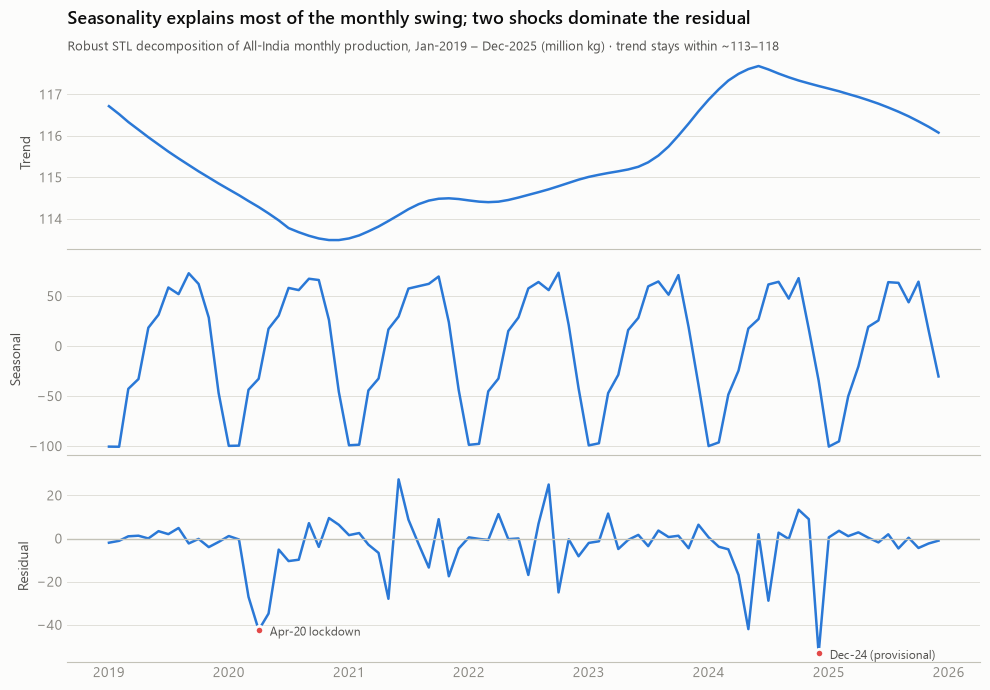

In [9]:
stl = STL(india.loc[:"2025-12"], period=12, trend=37, robust=True).fit()  # 37-month trend window avoids end-point swing
fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
for ax, comp, lab in zip(axes, (stl.trend, stl.seasonal, stl.resid), ("Trend", "Seasonal", "Residual")):
    ax.plot(comp.index, comp.values, color=CAT[0], linewidth=1.8)
    ax.set_ylabel(lab)
axes[2].axhline(0, color=BASE, linewidth=1)
for d, lab in (("2020-04-01", "Apr-20 lockdown"), ("2024-12-01", "Dec-24 (provisional)")):
    axes[2].annotate(lab, (pd.Timestamp(d), stl.resid[d]), xytext=(8, -4), textcoords="offset points",
                     fontsize=8.5, color=INK2)
    axes[2].plot(pd.Timestamp(d), stl.resid[d], "o", color=CAT[7], markersize=6,
                 markeredgecolor=SURFACE, markeredgewidth=2)
titled(axes[0], "Seasonality explains most of the monthly swing; two shocks dominate the residual",
       "Robust STL decomposition of All-India monthly production, Jan-2019 – Dec-2025 (million kg) · trend stays within ~113–118")
STATS["stl"] = {"seasonal_strength": round(max(0, 1 - stl.resid.var() / (stl.seasonal + stl.resid).var()), 3),
                "trend_strength": round(max(0, 1 - stl.resid.var() / (stl.trend + stl.resid).var()), 3)}
print(STATS["stl"])
save(fig, "08_stl_decomposition.png")

## 3. Machine-learning model — 12-month-ahead production forecast

**Task.** At the end of each financial year, forecast every month of the next
financial year for each of the 18 additive series (9 producing areas × big/small
growers). Summing the series gives zone and All-India forecasts.

**Features (all known ≥12 months in advance):** production in the same month 1 and
2 years earlier, the median and mean of that calendar month across all prior
years, month (cyclical + one-hot), area, grower type, and a flag when the
year-ago month was a known disruption (Apr-May 2020 lockdown, Dec-2024 provisional
shortfall). Disrupted months are excluded as training *targets* but kept in evaluation.

**Evaluation.** Rolling-origin backtest over four financial years (2022-23 →
2025-26): train on everything before the year, predict the whole year. Metrics
are computed on the All-India monthly total (MAE, RMSE, WAPE) and on the annual
total. Models are compared with two seasonal baselines.

In [10]:
leaf = pd.read_csv(DATA / "monthly_area_grower.csv", parse_dates=["date"])
leaf["series"] = leaf["area"] + " | " + leaf["grower"]
panel = leaf.pivot(index="date", columns="series", values="production_mkg").asfreq("MS")
future = pd.date_range(panel.index.max() + pd.offsets.MonthBegin(), periods=12, freq="MS")
panel = panel.reindex(panel.index.append(future))
meta = leaf.drop_duplicates("series").set_index("series")[["zone", "area", "grower"]]
DISRUPTED = pd.DatetimeIndex(["2020-03-01", "2020-04-01", "2020-05-01", "2024-12-01"])

frames = []
for s in panel.columns:
    y = panel[s]
    lag12 = y.shift(12)
    h = pd.DataFrame({"v": lag12, "m": y.index.month}, index=y.index)
    frames.append(pd.DataFrame({
        "date": y.index, "series": s, "y": y.values,
        "lag12": lag12.values, "lag24": y.shift(24).values,
        "hist_median": h.groupby("m")["v"].transform(lambda v: v.expanding().median()).values,
        "hist_mean": h.groupby("m")["v"].transform(lambda v: v.expanding().mean()).values,
    }))
data = pd.concat(frames, ignore_index=True).join(meta, on="series")
data["lag24"] = data["lag24"].fillna(data["lag12"])
data["month_num"] = data.date.dt.month.astype(str)
data["month_sin"] = np.sin(2 * np.pi * data.date.dt.month / 12)
data["month_cos"] = np.cos(2 * np.pi * data.date.dt.month / 12)
data["lag12_disrupted"] = (data.date - pd.DateOffset(months=12)).isin(DISRUPTED).astype(int)
data["target_disrupted"] = data.date.isin(DISRUPTED)
data = data[data.lag12.notna()].reset_index(drop=True)

NUM = ["lag12", "lag24", "hist_median", "hist_mean", "month_sin", "month_cos", "lag12_disrupted"]
CATS = ["area", "grower", "month_num"]
FEATURES = NUM + CATS
print(f"Model table: {len(data):,} rows ({data.y.notna().sum():,} with known target), "
      f"{data.series.nunique()} series, features: {FEATURES}")


def pipe(model, scale: bool) -> Pipeline:
    pre = ColumnTransformer([
        ("num", StandardScaler() if scale else "passthrough", NUM),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATS)])
    return Pipeline([("pre", pre), ("model", model)])


MODELS = {
    "Seasonal naive": None,           # same month last year
    "Seasonal median": None,          # median of that month in all prior years
    "Ridge regression": lambda: pipe(Ridge(alpha=1.0), True),
    "Random forest": lambda: pipe(RandomForestRegressor(n_estimators=500, min_samples_leaf=2,
                                                        random_state=42, n_jobs=-1), False),
    "Gradient boosting": lambda: pipe(HistGradientBoostingRegressor(
        max_iter=400, learning_rate=0.05, max_leaf_nodes=15, min_samples_leaf=10,
        l2_regularization=1.0, random_state=42), False),
}
FOLDS = ["2022-23", "2023-24", "2024-25", "2025-26"]


def predict(name, train, test):
    if name == "Seasonal naive":
        return test["lag12"].values, None
    if name == "Seasonal median":
        return test["hist_median"].values, None
    m = MODELS[name]()
    m.fit(train[FEATURES], train["y"])
    return np.clip(m.predict(test[FEATURES]), 0, None), m


preds, metrics, fitted = [], [], {}
for fold in FOLDS:
    start = pd.Timestamp(f"{fold[:4]}-04-01")
    end = start + pd.DateOffset(months=12)
    train = data[(data.date < start) & data.y.notna() & ~data.target_disrupted]
    test = data[(data.date >= start) & (data.date < end)]
    for name in MODELS:
        p, m = predict(name, train, test)
        fitted[(fold, name)] = (m, test)
        out = test[["date", "series", "zone", "area", "grower", "y"]].assign(pred=p, model=name, fold=fold)
        preds.append(out)
        agg = out.groupby("date")[["y", "pred"]].sum()
        metrics.append({
            "fold": fold, "model": name, "train_rows": len(train),
            "india_MAE": mean_absolute_error(agg.y, agg.pred),
            "india_RMSE": mean_squared_error(agg.y, agg.pred) ** 0.5,
            "india_WAPE_pct": 100 * (agg.y - agg.pred).abs().sum() / agg.y.sum(),
            "annual_error_pct": 100 * (agg.pred.sum() / agg.y.sum() - 1),
            "series_WAPE_pct": 100 * (out.y - out.pred).abs().sum() / out.y.sum(),
            "series_R2": r2_score(out.y, out.pred),
        })
preds = pd.concat(preds, ignore_index=True)
bt = pd.DataFrame(metrics)
summary = (bt.groupby("model")[["india_MAE", "india_RMSE", "india_WAPE_pct", "series_WAPE_pct", "series_R2"]]
           .mean().assign(abs_annual_error_pct=bt.assign(a=bt.annual_error_pct.abs()).groupby("model")["a"].mean())
           .sort_values("india_WAPE_pct"))
BEST = summary.index[0]
ML_MODELS = ["Ridge regression", "Random forest", "Gradient boosting"]
BEST_ML = summary.loc[ML_MODELS].sort_values("india_WAPE_pct").index[0]
BENCH = "Seasonal median"
bt.round(3).to_csv(REPORTS / "model_backtest_by_fold.csv", index=False)
summary.round(3).to_csv(REPORTS / "model_backtest_summary.csv")
preds.to_csv(REPORTS / "backtest_predictions.csv", index=False)
print("Backtest by fold (All-India WAPE %):")
print(bt.pivot(index="model", columns="fold", values="india_WAPE_pct").round(2).to_string())
print("\nMean over folds:")
print(summary.round(3).to_string())
print(f"\nLowest error overall: {BEST} | best machine-learning model: {BEST_ML}")

# Is the difference real? Paired Wilcoxon signed-rank test on the 48 All-India monthly
# absolute errors (4 folds x 12 months) - a non-parametric Diebold-Mariano-style comparison.
mon_err = (preds.groupby(["model", "fold", "date"])[["y", "pred"]].sum()
           .assign(ae=lambda d: (d.y - d.pred).abs())["ae"].unstack("model"))
tests = {}
for a, b in ((BEST_ML, BENCH), (BEST_ML, "Seasonal naive"), (BENCH, "Seasonal naive")):
    w = stats.wilcoxon(mon_err[a], mon_err[b])
    tests[f"{a} vs {b}"] = {"mean_abs_err_a": round(mon_err[a].mean(), 2),
                           "mean_abs_err_b": round(mon_err[b].mean(), 2),
                           "wilcoxon_p": round(w.pvalue, 4)}
print(pd.DataFrame(tests).T.to_string())
STATS["model"] = {"lowest_error": BEST, "best_ml": BEST_ML, "summary": summary.round(3).to_dict("index"),
                  "by_fold_wape": bt.pivot(index="model", columns="fold", values="india_WAPE_pct").round(2).to_dict("index"),
                  "significance_tests": tests}

Model table: 1,566 rows (1,350 with known target), 18 series, features: ['lag12', 'lag24', 'hist_median', 'hist_mean', 'month_sin', 'month_cos', 'lag12_disrupted', 'area', 'grower', 'month_num']


Backtest by fold (All-India WAPE %):
fold               2022-23  2023-24  2024-25  2025-26
model                                                
Gradient boosting    12.78     7.44    16.73     8.64
Random forest        10.95     6.41    14.89     8.10
Ridge regression     12.85     7.80    13.76     9.57
Seasonal median      10.45     6.80    12.90     7.86
Seasonal naive       14.85     9.45    12.34    16.09

Mean over folds:
                   india_MAE  india_RMSE  india_WAPE_pct  series_WAPE_pct  series_R2  abs_annual_error_pct
model                                                                                                     
Seasonal median       10.699      13.635           9.501           14.823      0.966                 3.199
Random forest         11.341      14.290          10.090           15.421      0.960                 3.619
Ridge regression      12.402      15.147          10.996           16.786      0.965                 2.774
Gradient boosting     12.813    

**Reading the results.** All three ML models clearly beat the *seasonal naive*
baseline (copying last year), but none beats the *seasonal median* (the typical
level of that calendar month across all prior years). Twelve months ahead, the
only information is history, and year-to-year departures from the seasonal norm
are driven by weather, which past production cannot predict. Beating the robust
seasonal profile would need exogenous drivers (rainfall, temperature, prices).

Fold 2024-25 has the highest errors: its Apr-Dec 2024 actuals are the Tea
Board's *provisional* monthly figures, including the anomalously low Dec-2024.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


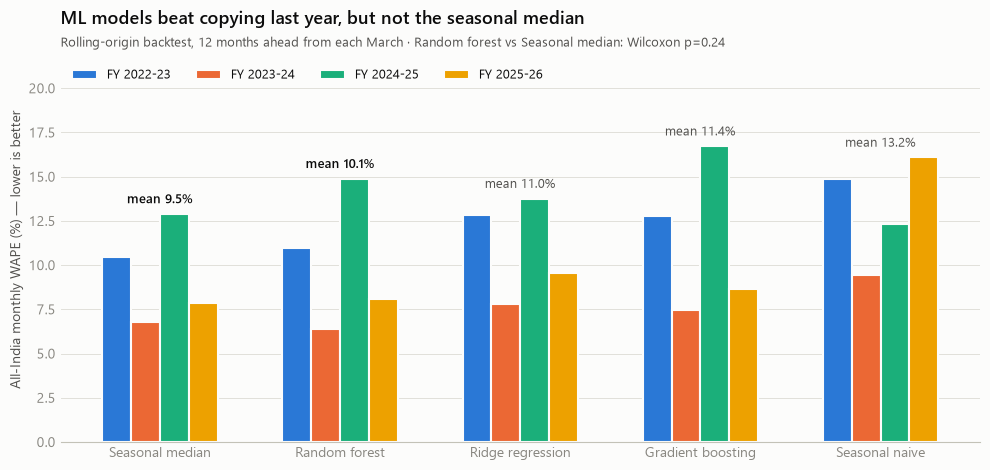

In [11]:
order = summary.index.tolist()
fig, ax = plt.subplots(figsize=(10, 4.8))
w = 0.16
fold_colors = dict(zip(FOLDS, CAT[:4]))
pv = bt.pivot(index="model", columns="fold", values="india_WAPE_pct").loc[order]
for i, f in enumerate(FOLDS):
    ax.bar(np.arange(len(order)) + (i - 1.5) * w, pv[f], width=w, color=fold_colors[f],
           edgecolor=SURFACE, linewidth=1.5, label=f"FY {f}")
for j, mdl in enumerate(order):
    hi = mdl in (BEST, BEST_ML)
    ax.text(j, pv.loc[mdl].max() + 0.6, f"mean {summary.loc[mdl, 'india_WAPE_pct']:.1f}%", ha="center",
            fontsize=9, color=INK if hi else INK2, fontweight="semibold" if hi else "normal")
ax.set_xticks(range(len(order)), order)
ax.set_ylabel("All-India monthly WAPE (%) — lower is better")
ax.legend(ncol=4, loc="upper left")
ax.set_ylim(0, pv.values.max() * 1.3)
p_ml = tests[f"{BEST_ML} vs {BENCH}"]["wilcoxon_p"]
titled(ax, "ML models beat copying last year, but not the seasonal median",
       f"Rolling-origin backtest, 12 months ahead from each March · {BEST_ML} vs {BENCH}: "
       f"Wilcoxon p={p_ml:.2f}")
save(fig, "09_model_comparison.png")

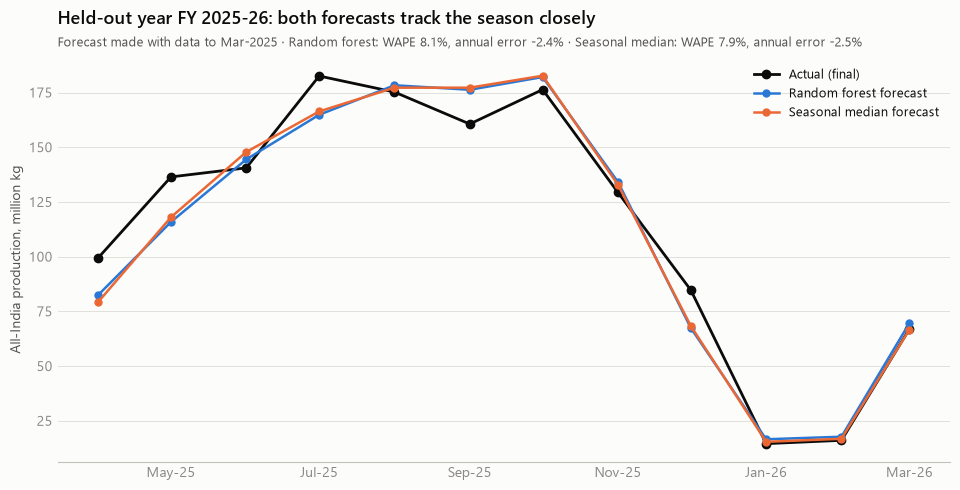

In [12]:
show = [BEST_ML, BENCH]
last = preds[(preds.fold == "2025-26") & preds.model.isin(show)]
agg = last.groupby(["model", "date"])[["y", "pred"]].sum().reset_index()
act = agg[agg.model == BEST_ML].set_index("date")["y"]
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(act.index, act.values, color=INK, marker="o", markersize=6, label="Actual (final)")
for mdl, col in zip(show, (CAT[0], CAT[1])):
    s = agg[agg.model == mdl].set_index("date")["pred"]
    ax.plot(s.index, s.values, color=col, marker="o", markersize=5, linewidth=1.8, label=f"{mdl} forecast")
ax.set_ylabel("All-India production, million kg")
ax.xaxis.set_major_formatter(mpl.dates.DateFormatter("%b-%y"))
ax.legend(loc="upper right")
m26 = bt[(bt.fold == "2025-26")].set_index("model")
titled(ax, "Held-out year FY 2025-26: both forecasts track the season closely",
       f"Forecast made with data to Mar-2025 · {BEST_ML}: WAPE {m26.loc[BEST_ML, 'india_WAPE_pct']:.1f}%, "
       f"annual error {m26.loc[BEST_ML, 'annual_error_pct']:+.1f}% · {BENCH}: WAPE "
       f"{m26.loc[BENCH, 'india_WAPE_pct']:.1f}%, annual error {m26.loc[BENCH, 'annual_error_pct']:+.1f}%")
save(fig, "10_actual_vs_forecast_FY2025-26.png")

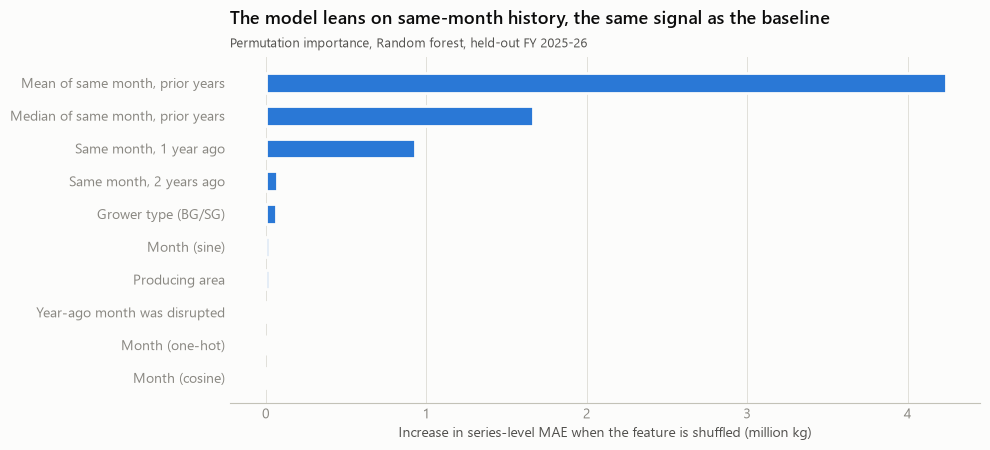

                       actual_mkg  forecast_mkg  WAPE_pct  annual_error_pct
area                                                                       
Assam Valley               650.09        623.14     10.02             -4.15
Dooars                     231.19        234.45     18.61              1.41
Terai                      187.51        174.42     18.99             -6.98
Tamil Nadu                 167.91        167.54     13.21             -0.22
Kerala                      57.51         63.71     16.01             10.78
Others (NE & HP etc.)       40.14         35.71     18.98            -11.03
Cachar                      38.07         39.23     10.23              3.03
Darjeeling                   5.98          6.04     25.20              1.05
Karnataka                    4.34          5.38     35.25             23.94


In [13]:
# Which inputs matter? Permutation importance of the best ML model on held-out FY 2025-26
mdl_best, test_best = fitted[("2025-26", BEST_ML)]
pi = permutation_importance(mdl_best, test_best[FEATURES], test_best["y"], n_repeats=20,
                            random_state=42, scoring="neg_mean_absolute_error")
LABELS = {"lag12": "Same month, 1 year ago", "lag24": "Same month, 2 years ago",
          "hist_median": "Median of same month, prior years", "hist_mean": "Mean of same month, prior years",
          "month_sin": "Month (sine)", "month_cos": "Month (cosine)", "month_num": "Month (one-hot)",
          "lag12_disrupted": "Year-ago month was disrupted", "area": "Producing area", "grower": "Grower type (BG/SG)"}
imp = pd.Series(pi.importances_mean, index=[LABELS[f] for f in FEATURES]).sort_values()
STATS["model"]["permutation_importance_mae_increase"] = imp.round(3).to_dict()
fig, ax = plt.subplots(figsize=(10, 4.6))
ax.barh(imp.index, imp.values, color=CAT[0], height=0.6, edgecolor=SURFACE, linewidth=2)
ax.grid(axis="y", visible=False)
ax.grid(axis="x")
ax.set_xlabel("Increase in series-level MAE when the feature is shuffled (million kg)")
titled(ax, "The model leans on same-month history, the same signal as the baseline",
       f"Permutation importance, {BEST_ML}, held-out FY 2025-26")
save(fig, "11_feature_importance.png")

area_err = (preds[(preds.fold == "2025-26") & (preds.model == BEST_ML)]
            .groupby("area").apply(lambda d: pd.Series({
                "actual_mkg": d.y.sum(), "forecast_mkg": d.pred.sum(),
                "WAPE_pct": 100 * (d.y - d.pred).abs().sum() / d.y.sum()})))
area_err["annual_error_pct"] = 100 * (area_err.forecast_mkg / area_err.actual_mkg - 1)
print(area_err.round(2).sort_values("actual_mkg", ascending=False).to_string())
area_err.round(3).to_csv(REPORTS / "model_error_by_area_FY2025-26.csv")

## 4. Forecast for FY 2026-27 (Apr-2026 – Mar-2027)
The best ML model is refit on all data to March 2026; the seasonal-median
benchmark is shown alongside. The band is an approximate 80% interval built from
the ML model's All-India monthly backtest errors.

            ml_forecast_mkg  lower_80  upper_80  benchmark_forecast_mkg  ml_forecast_North India  ml_forecast_South India
month                                                                                                                    
2026-04-01             88.8      78.2     106.6                    82.2                     68.7                     20.1
2026-05-01            123.9     109.1     148.8                   124.2                    100.9                     23.0
2026-06-01            148.9     131.1     178.7                   149.0                    123.5                     25.4
2026-07-01            160.4     141.2     192.5                   168.2                    139.9                     20.5
2026-08-01            176.0     155.0     211.3                   178.9                    157.7                     18.4
2026-09-01            170.9     150.5     205.2                   172.7                    148.6                     22.3
2026-10-01            18

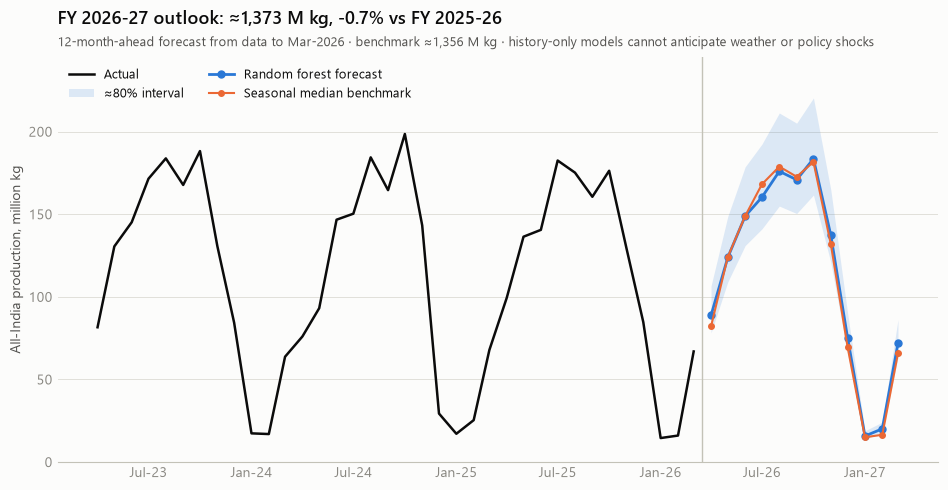

In [14]:
train_all = data[data.y.notna() & ~data.target_disrupted]
fut = data[data.date.isin(future)]
fut = fut.assign(pred_ml=predict(BEST_ML, train_all, fut)[0], pred_bench=predict(BENCH, train_all, fut)[0])
fc = fut.groupby("date")["pred_ml"].sum()
fc_b = fut.groupby("date")["pred_bench"].sum()
fc_zone = fut.groupby(["date", "zone"])["pred_ml"].sum().unstack()
bt_ml = preds[preds.model == BEST_ML].groupby(["fold", "date"])[["y", "pred"]].sum()
rel = (bt_ml.y / bt_ml.pred - 1)
lo_q, hi_q = rel.quantile(0.10), rel.quantile(0.90)
forecast = pd.DataFrame({"ml_forecast_mkg": fc, "lower_80": fc * (1 + lo_q),
                         "upper_80": fc * (1 + hi_q), "benchmark_forecast_mkg": fc_b}).join(
    fc_zone.add_prefix("ml_forecast_"))
forecast.index.name = "month"
forecast.round(2).to_csv(REPORTS / "forecast_FY2026-27.csv")
fy_prev = fy.loc["2025-26", "All India"]
STATS["forecast_FY2026_27"] = {
    "model": BEST_ML, "total_mkg": round(fc.sum(), 1), "vs_FY2025_26_pct": round(100 * (fc.sum() / fy_prev - 1), 2),
    # annual range from the model's own annual backtest errors (summing monthly bounds would overstate it)
    "annual_range_from_backtest_mkg": [round(fc.sum() / (1 + bt[bt.model == BEST_ML].annual_error_pct.max() / 100), 1),
                                       round(fc.sum() / (1 + bt[bt.model == BEST_ML].annual_error_pct.min() / 100), 1)],
    "north_mkg": round(fc_zone["North India"].sum(), 1), "south_mkg": round(fc_zone["South India"].sum(), 1),
    "benchmark": BENCH, "benchmark_total_mkg": round(fc_b.sum(), 1),
    "benchmark_vs_FY2025_26_pct": round(100 * (fc_b.sum() / fy_prev - 1), 2)}
print(forecast.round(1).to_string())
print(STATS["forecast_FY2026_27"])

hist = india.loc["2023-04":]
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(hist.index, hist.values, color=INK, linewidth=1.8, label="Actual")
ax.fill_between(fc.index, forecast.lower_80, forecast.upper_80, color=CAT[0], alpha=0.15, linewidth=0,
                label="≈80% interval")
ax.plot(fc.index, fc.values, color=CAT[0], marker="o", markersize=5, label=f"{BEST_ML} forecast")
ax.plot(fc_b.index, fc_b.values, color=CAT[1], marker="o", markersize=4, linewidth=1.5,
        label=f"{BENCH} benchmark")
ax.axvline(pd.Timestamp("2026-03-15"), color=BASE, linewidth=1)
ax.xaxis.set_major_formatter(mpl.dates.DateFormatter("%b-%y"))
ax.set_ylabel("All-India production, million kg")
ax.set_ylim(0, 245)
ax.legend(loc="upper left", ncol=2)
titled(ax, f"FY 2026-27 outlook: ≈{fc.sum():,.0f} M kg, "
           f"{STATS['forecast_FY2026_27']['vs_FY2025_26_pct']:+.1f}% vs FY 2025-26",
       f"12-month-ahead forecast from data to Mar-2026 · benchmark ≈{fc_b.sum():,.0f} M kg · history-only "
       "models cannot anticipate weather or policy shocks")
save(fig, "12_forecast_FY2026-27.png")

In [15]:
(REPORTS / "statistics.json").write_text(json.dumps(STATS, indent=2, default=float))
print("Saved figures to", FIG)
print("Saved statistics to", REPORTS / "statistics.json")

Saved figures to C:\Projects\DAV\reports\figures
Saved statistics to C:\Projects\DAV\reports\statistics.json
